# Modelos de ensamble — homogéneos, heterogéneos e híbridos CNN + tabular

**Proyecto:** GalMorphAI · Maestría en Inteligencia Artificial Aplicada · Fase CRISP-ML: *Modelado* (ensambles)

**Pregunta:** ¿combinar modelos supera al mejor modelo individual (la CNN ResNet18 p99.9 + TTA)? Se estudian tres familias:
1. **Ensambles homogéneos** (un solo tipo de modelo base): Random Forest, ExtraTrees, *bagging* de árboles, HistGradientBoosting y AdaBoost. El notebook de modelos alternativos solo contiene modelos individuales; los ensambles de árboles se construyen y ajustan aquí.
2. **Ensambles heterogéneos tabulares**: votación suave (simple y ponderada) y *stacking* con un metamodelo logístico sobre los modelos alternativos.
3. **Ensambles híbridos CNN + tabular**: combinan la probabilidad de la CNN (que ve la imagen) con la de modelos sobre las características morfológicas (que resumen elipticidad, modos de Fourier, concentración, etc.). La hipótesis es que se equivocan en galaxias distintas.

**Reglas.** Todas las decisiones (hiperparámetros, pesos, metamodelo, candidato final) se toman con predicciones fuera de pliegue (OOF) de entrenamiento o con `train_es`; validación se usa para comparar; **prueba se reserva**. El conjunto de prueba ya se usó una vez (CNN-14); la celda `9.-` permite evaluar en prueba **solo el candidato elegido**, una vez, y lo declara como segunda consulta.

**Requisitos previos:** notebooks de FE, baseline, CNN y modelos alternativos (Parte A) ejecutados.

## Configuración e importacion de librerias

In [ ]:
# Configuración
from pathlib import Path
import sys, io, json, time, random, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.stats import loguniform, randint, uniform, spearmanr
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score, precision_score, recall_score,
                             balanced_accuracy_score, brier_score_loss, precision_recall_curve)

warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 170); pd.set_option('display.max_columns', 40)

# EDITAR ESTAS RUTAS en tu equipo
FE_DIR = Path('/Users/geo/Proyecto_Integrador/Modelos/fe')
BL_DIR = Path('/Users/geo/Proyecto_Integrador/Modelos/baseline')
CNN_DIR = Path('/Users/geo/Proyecto_Integrador/Modelos/cnn')
ALT_DIR = Path('/Users/geo/Proyecto_Integrador/Modelos/alternativos')
ENS_DIR = Path('/Users/geo/Proyecto_Integrador/Modelos/ensambles')
ENS_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
N_BOOTSTRAP = 1000
N_ITER_HOMOG = 20            # combinaciones por búsqueda de cada ensamble de árboles
TOP_K_VOTING = 3             # modelos en la votación suave
RUN_HYBRID = True            # requiere PyTorch y la caché de la CNN (o puntuaciones_cnn.csv ya calculado)
USE_TUNED_CNN = 'auto'       # 'auto': usa la CNN ajustada solo si ALT-7 la adoptó
FEATURE_MS_PER_IMAGE = 90.0  # costo medido de extraer características (BL / CNN-11)
RUN_FINAL_TEST = True       # ← cambiar a True SOLO al final, una vez (9)

random.seed(SEED); np.random.seed(SEED)
CLASS_COLORS = {0: '#2a78d6', 1: '#eb6834'}
NEUTRAL = '#8a8984'
BARS_SHORT = {-0.5: 'ambigua', 0.0: 'sin barra', 0.25: 'débil', 0.5: 'visible', 0.75: 'prominente', 1.0: 'muy evidente'}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'axes.titleweight': 'bold'})
def savefig(name):
    plt.savefig(ENS_DIR / f'{name}.png', bbox_inches='tight')
CNN_REF = 'CNN ResNet18 p99.9 + TTA (final)'
CNN_NAME = 'CNN final'

## 1.- Datos, modelos alternativos y predicciones guardadas

In [ ]:
# 1.- Carga
data = pd.read_csv(FE_DIR / 'dataset_caracteristicas.csv')
alt = joblib.load(ALT_DIR / 'modelos_alternativos.joblib')
FEATURES = alt['features']
alt_cv = pd.read_csv(ALT_DIR / 'busqueda_tabular_cv.csv', index_col=0)
oof_df = pd.read_csv(ALT_DIR / 'oof_entrenamiento_alternativos.csv')
valp_df = pd.read_csv(ALT_DIR / 'predicciones_validacion_alternativos.csv')

train = data[data['split'] == 'train'].reset_index(drop=True)
val = data[data['split'] == 'validation'].reset_index(drop=True)
X_tr, y_tr, g_tr = train[FEATURES], train['label'].to_numpy(), train['group_id'].to_numpy()
X_va, y_va = val[FEATURES], val['label'].to_numpy()
assert oof_df['name'].tolist() == train['name'].tolist() and valp_df['name'].tolist() == val['name'].tolist(), \
    'Las predicciones de ALT no corresponden al mismo orden de galaxias: vuelve a ejecutar ALT-4'
CV_SPLITS = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_tr, y_tr, groups=g_tr))

BASE_NAMES = list(alt['models'])
OOF = {n: oof_df[f'oof__{n}'].to_numpy() for n in BASE_NAMES}
VAL = {n: valp_df[f'score__{n}'].to_numpy() for n in BASE_NAMES}
labels_va = pd.Series(y_va, index=val['name'])
ref_scores = {}
if (BL_DIR / 'predicciones_validacion_cnn.csv').exists():
    ref_scores[CNN_REF] = pd.read_csv(BL_DIR / 'predicciones_validacion_cnn.csv').set_index('name')['score']
print(f'Entrenamiento {len(train)} · validación {len(val)} · modelos base: {BASE_NAMES}')

Entrenamiento 6823 · validación 1464 · modelos base: ['Regresión logística', 'Análisis discriminante lineal', 'Naive Bayes gaussiano', 'kNN', 'Árbol de decisión', 'SVM RBF', 'Perceptrón multicapa (MLP)']


In [ ]:
# 1.1.- Funciones de evaluación
def ece_score(y, p, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1); idx = np.clip(np.digitize(p, bins) - 1, 0, n_bins - 1)
    return sum(abs(y[idx == b].mean() - p[idx == b].mean()) * (idx == b).mean() for b in range(n_bins) if (idx == b).any())

def bootstrap_ci(y, p, n=N_BOOTSTRAP, seed=SEED):
    rng = np.random.default_rng(seed); vals = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            vals.append(average_precision_score(y[i], p[i]))
    return np.percentile(vals, [2.5, 97.5])

def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    return float(thr[np.nanargmax(f1[:-1])]) if len(thr) else 0.5

def full_metrics(y, p, thr):
    pred = (p >= thr).astype(int); lo, hi = bootstrap_ci(y, p)
    return {'PR_AUC': average_precision_score(y, p), 'PR_AUC_IC95_inf': lo, 'PR_AUC_IC95_sup': hi,
            'ROC_AUC': roc_auc_score(y, p), 'umbral': thr, 'F1_barra': f1_score(y, pred, zero_division=0),
            'precision_barra': precision_score(y, pred, zero_division=0), 'recall_barra': recall_score(y, pred, zero_division=0),
            'exactitud_bal': balanced_accuracy_score(y, pred), 'Brier': brier_score_loss(y, p), 'ECE': ece_score(y, p)}

def paired_bootstrap(sa, sb, labels, n=N_BOOTSTRAP, seed=SEED):
    common = sa.index.intersection(sb.index).intersection(labels.index)
    pa, pb_, y = sa[common].to_numpy(), sb[common].to_numpy(), labels[common].to_numpy()
    rng = np.random.default_rng(seed); d = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            d.append(average_precision_score(y[i], pa[i]) - average_precision_score(y[i], pb_[i]))
    return average_precision_score(y, pa) - average_precision_score(y, pb_), tuple(np.percentile(d, [2.5, 97.5])), len(common)

def logit(p, eps=1e-6):
    p = np.clip(np.asarray(p, float), eps, 1 - eps); return np.log(p / (1 - p))
def sigmoid(x): return 1 / (1 + np.exp(-x))

RESULTS = {}      # nombre → dict(familia, val_score (Series), umbral, cv_pr_auc, componentes)
def register(name, family, p_val, thr, cv_pr=np.nan, components=None, names=None):
    RESULTS[name] = {'familia': family, 'score': pd.Series(np.asarray(p_val), index=val['name'] if names is None else names),
                     'umbral': thr, 'PR_AUC_cv': cv_pr, 'componentes': components or [name]}

for n in BASE_NAMES:   # modelos individuales como referencia
    register(f'{n} (individual)', 'individual tabular', VAL[n], alt['thresholds'][n], average_precision_score(y_tr, OOF[n]), [n])

# Parte 1 — Ensambles homogéneos
## 2.- Ensambles de árboles: *bagging* y *boosting*
- ***Bagging*** (Breiman, 1996): promedia árboles entrenados en remuestras *bootstrap*; reduce **varianza**. **Random Forest** además submuestrea variables en cada división y **ExtraTrees** elige umbrales al azar, lo que decorrelaciona aún más los árboles.
- ***Boosting***: suma secuencial de árboles poco profundos donde cada uno corrige a los anteriores; reduce **sesgo**. **AdaBoost** (Freund y Schapire, 1997) repondera los ejemplos mal clasificados; **HistGradientBoosting** ajusta el gradiente de la pérdida (versión moderna, con histogramas).

Los cinco se ajustan con búsqueda aleatoria y los mismos 5 pliegues por grupos que los modelos individuales. Se comparan con el **Árbol de decisión individual** del notebook de alternativos: así se mide cuánto aporta combinar árboles.

In [ ]:
# 2.- Búsqueda de los ensambles de árboles (RF, ExtraTrees, HGB, bagging, AdaBoost)
def unscaled(clf):
    return Pipeline([('imp', SimpleImputer(strategy='median')), ('clf', clf)])
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
HOMOG = {
    'Random Forest': (unscaled(RandomForestClassifier(class_weight='balanced_subsample', n_jobs=-1, random_state=SEED)),
        {'clf__n_estimators': randint(200, 701), 'clf__max_depth': [None, 8, 12, 16, 24],
         'clf__min_samples_leaf': randint(1, 21), 'clf__max_features': ['sqrt', 'log2', 0.3, 0.5]}),
    'ExtraTrees': (unscaled(ExtraTreesClassifier(class_weight='balanced_subsample', n_jobs=-1, random_state=SEED)),
        {'clf__n_estimators': randint(200, 701), 'clf__max_depth': [None, 8, 12, 16, 24],
         'clf__min_samples_leaf': randint(1, 21), 'clf__max_features': ['sqrt', 'log2', 0.3, 0.5]}),
    'HistGradientBoosting': (unscaled(HistGradientBoostingClassifier(class_weight='balanced', max_iter=600,
                                                                     early_stopping=True, random_state=SEED)),
        {'clf__learning_rate': loguniform(1e-2, 3e-1), 'clf__max_leaf_nodes': randint(8, 65),
         'clf__min_samples_leaf': randint(10, 121), 'clf__l2_regularization': loguniform(1e-4, 1e1),
         'clf__max_features': uniform(0.3, 0.7)}),
    'Bagging de árboles': (unscaled(BaggingClassifier(estimator=DecisionTreeClassifier(class_weight='balanced', random_state=SEED),
                                                      n_jobs=-1, random_state=SEED)),
        {'clf__n_estimators': randint(100, 401), 'clf__max_samples': uniform(0.4, 0.6), 'clf__max_features': uniform(0.4, 0.6),
         'clf__estimator__min_samples_leaf': randint(1, 31), 'clf__estimator__max_depth': [None, 8, 12, 16]}),
    'AdaBoost (árboles poco profundos)': (unscaled(AdaBoostClassifier(estimator=DecisionTreeClassifier(class_weight='balanced', random_state=SEED),
                                                                    random_state=SEED)),
        {'clf__n_estimators': randint(100, 501), 'clf__learning_rate': loguniform(1e-2, 1e0),
         'clf__estimator__max_depth': [1, 2, 3], 'clf__estimator__min_samples_leaf': randint(5, 51)}),
}
homog_file = ENS_DIR / 'busquedas_homogeneos.joblib'
homog = joblib.load(homog_file) if homog_file.exists() else {}
rows = []
for name, (pipe, space) in HOMOG.items():
    if name not in homog or len(homog[name]['search'].cv_results_['params']) != N_ITER_HOMOG:
        t0 = time.perf_counter()
        rs = RandomizedSearchCV(pipe, space, n_iter=N_ITER_HOMOG, scoring='average_precision', cv=CV_SPLITS,
                                n_jobs=-1, random_state=SEED, return_train_score=True).fit(X_tr, y_tr)
        oof_h = cross_val_predict(clone(rs.best_estimator_), X_tr, y_tr, cv=CV_SPLITS, method='predict_proba')[:, 1]
        homog[name] = {'search': rs, 'oof': oof_h, 'sec': time.perf_counter() - t0}
        joblib.dump(homog, homog_file)
    rs, oof_h = homog[name]['search'], homog[name]['oof']
    OOF[name] = oof_h; VAL[name] = rs.best_estimator_.predict_proba(X_va)[:, 1]
    thr = best_f1_threshold(y_tr, oof_h)
    register(name, 'homogéneo', VAL[name], thr, average_precision_score(y_tr, oof_h), [name])
    i = rs.best_index_
    rows.append({'modelo': name, 'PR_AUC_cv': rs.cv_results_['mean_test_score'][i], 'std_cv': rs.cv_results_['std_test_score'][i],
                 'brecha_train_cv': rs.cv_results_['mean_train_score'][i] - rs.cv_results_['mean_test_score'][i],
                 'PR_AUC_val': average_precision_score(y_va, VAL[name]), 'seg': homog[name]['sec'],
                 'mejores_hiperparámetros': {k.replace('clf__', ''): (round(v, 4) if isinstance(v, float) else v) for k, v in rs.best_params_.items()}})
homog_tab = pd.DataFrame(rows).set_index('modelo')
# Referencia: el árbol de decisión individual (ALT) frente a los ensambles de árboles
if 'Árbol de decisión' in alt_cv.index:
    homog_tab.loc['Árbol de decisión (individual, ALT)', ['PR_AUC_cv', 'std_cv', 'brecha_train_cv', 'PR_AUC_val']] = [
        alt_cv.loc['Árbol de decisión', 'PR_AUC_cv_media'], alt_cv.loc['Árbol de decisión', 'PR_AUC_cv_std'],
        alt_cv.loc['Árbol de decisión', 'brecha_train_cv'], average_precision_score(y_va, VAL['Árbol de decisión'])]
homog_tab = homog_tab.sort_values('PR_AUC_cv', ascending=False)
display(homog_tab.round(4)); homog_tab.to_csv(ENS_DIR / 'ensambles_homogeneos.csv')

/Users/geo/Proyecto_Integrador/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/geo/Proyecto_Integrador/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/geo/Proyecto_Integrador/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/geo/Proyecto_Integrador/

,PR_AUC_cv,std_cv,brecha_train_cv,PR_AUC_val,seg,mejores_hiperparámetros
modelo,,,,,,
HistGradientBoosting,0.7665,0.0170,0.1241,0.7645,61.7678,"{'l2_regularization': 0.0169, 'learning_rate':..."
Bagging de árboles,0.7588,0.0128,0.1303,0.7466,123.7930,"{'estimator__max_depth': 12, 'estimator__min_s..."
Random Forest,0.7580,0.0115,0.1487,0.7480,161.4524,"{'max_depth': 24, 'max_features': 0.5, 'min_sa..."
ExtraTrees,0.7491,0.0130,0.1949,0.7421,46.0448,"{'max_depth': 24, 'max_features': 0.5, 'min_sa..."
AdaBoost (árboles poco profundos),0.6980,0.0159,0.0272,0.6911,69.3826,"{'estimator__max_depth': 3, 'estimator__min_sa..."
"Árbol de decisión (individual, ALT)",0.6669,0.0136,0.1077,0.6520,NaN,NaN


# Parte 2 — Ensambles heterogéneos tabulares
## 3.- Diversidad de los modelos base
Un ensamble solo mejora si los modelos **se equivocan en ejemplos distintos**. Se mide con las predicciones OOF de entrenamiento:
- correlación de Spearman entre puntuaciones (alta → modelos redundantes);
- tasa de desacuerdo entre las clases predichas con el umbral de cada modelo.

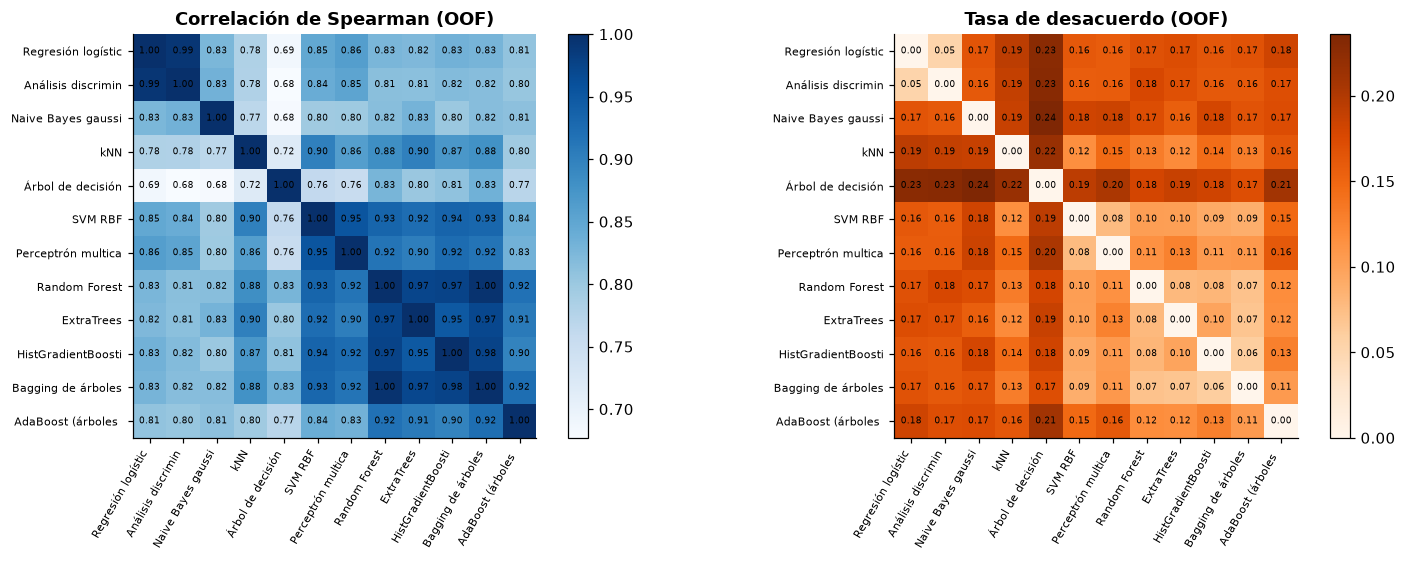

In [ ]:
# 3.- Diversidad (OOF de entrenamiento)
DIV_NAMES = BASE_NAMES + list(HOMOG)
oof_mat = pd.DataFrame({n: OOF[n] for n in DIV_NAMES})
corr = oof_mat.corr(method='spearman')
thr_oof = {n: best_f1_threshold(y_tr, OOF[n]) for n in DIV_NAMES}
pred_oof = pd.DataFrame({n: (OOF[n] >= thr_oof[n]).astype(int) for n in DIV_NAMES})
disagree = pd.DataFrame([[(pred_oof[a] != pred_oof[b]).mean() for b in DIV_NAMES] for a in DIV_NAMES], index=DIV_NAMES, columns=DIV_NAMES)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, M, title, cmap in [(axes[0], corr, 'Correlación de Spearman (OOF)', 'Blues'), (axes[1], disagree, 'Tasa de desacuerdo (OOF)', 'Oranges')]:
    im = ax.imshow(M.to_numpy(), cmap=cmap); ax.grid(False)
    short = [n[:18] for n in M.index]
    ax.set_xticks(range(len(M)), short, rotation=60, ha='right', fontsize=7); ax.set_yticks(range(len(M)), short, fontsize=7)
    for i in range(len(M)):
        for j in range(len(M)):
            ax.text(j, i, f'{M.iat[i, j]:.2f}', ha='center', va='center', fontsize=6)
    ax.set_title(title); plt.colorbar(im, ax=ax, fraction=.046)
plt.tight_layout(); savefig('ens3_diversidad'); plt.show()
corr.to_csv(ENS_DIR / 'diversidad_correlacion_oof.csv'); disagree.to_csv(ENS_DIR / 'diversidad_desacuerdo_oof.csv')

## 4.- Votación suave (simple y ponderada) y *stacking*
- **Votación suave:** promedio de probabilidades de los `TOP_K_VOTING` mejores modelos según PR-AUC OOF (equivale a `VotingClassifier(voting='soft')` con los mismos modelos ya ajustados). **Ponderada:** pesos en una rejilla del simplex (paso 0.1) elegidos por PR-AUC OOF.
- ***Stacking*** (Wolpert, 1992): un metamodelo (regresión logística sobre el logit de cada probabilidad base) aprende a combinar las predicciones **OOF** de todos los modelos base; en validación recibe las predicciones de los modelos base reajustados con todo el entrenamiento. Es exactamente lo que hace `StackingClassifier(cv=CV_SPLITS, stack_method='predict_proba')`, pero reutiliza los ajustes de ALT. La regularización C del metamodelo se elige con los mismos pliegues por grupos y su PR-AUC CV se estima con `cross_val_predict` sobre la matriz OOF (ligeramente optimista: los modelos base de cada pliegue vieron las otras galaxias).

Modelos de la votación: ['Perceptrón multicapa (MLP)', 'HistGradientBoosting', 'Bagging de árboles']
Pesos elegidos (OOF): {'Perceptrón multicapa (MLP)': 0.5, 'HistGradientBoosting': 0.5, 'Bagging de árboles': 0.0}
C del metamodelo = 0.1874


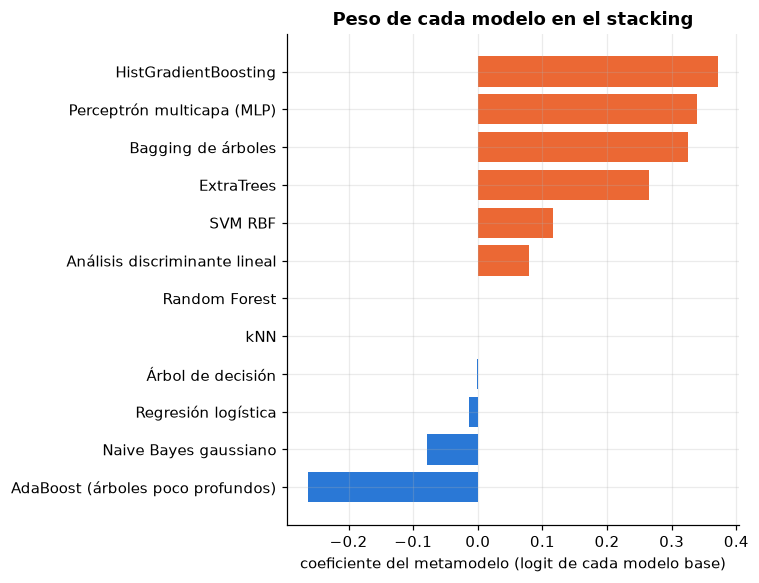

['/Users/geo/Proyecto_Integrador/Modelos/ensambles/ensambles_tabulares.joblib']

In [ ]:
# 4.- Votación y stacking
cv_rank = sorted(DIV_NAMES, key=lambda n: average_precision_score(y_tr, OOF[n]), reverse=True)
top = cv_rank[:TOP_K_VOTING]
print('Modelos de la votación:', top)

# Votación simple
oof_vote = np.mean([OOF[n] for n in top], axis=0); val_vote = np.mean([VAL[n] for n in top], axis=0)
register(f'Votación suave (top-{TOP_K_VOTING})', 'heterogéneo tabular', val_vote, best_f1_threshold(y_tr, oof_vote),
         average_precision_score(y_tr, oof_vote), top)

# Votación ponderada (pesos elegidos con OOF)
grid = [w for w in itertools.product(np.round(np.arange(0, 1.01, 0.1), 1), repeat=len(top)) if abs(sum(w) - 1) < 1e-9]
best_w, best_pr = None, -1
for w in grid:
    pr = average_precision_score(y_tr, sum(wi * OOF[n] for wi, n in zip(w, top)))
    if pr > best_pr: best_w, best_pr = w, pr
oof_wvote = sum(wi * OOF[n] for wi, n in zip(best_w, top)); val_wvote = sum(wi * VAL[n] for wi, n in zip(best_w, top))
register(f'Votación ponderada (top-{TOP_K_VOTING})', 'heterogéneo tabular', val_wvote, best_f1_threshold(y_tr, oof_wvote), best_pr, top)
print('Pesos elegidos (OOF):', {n: float(w) for n, w in zip(top, best_w)})

# Stacking con metamodelo logístico
Z_tr = np.column_stack([logit(OOF[n]) for n in DIV_NAMES]); Z_va = np.column_stack([logit(VAL[n]) for n in DIV_NAMES])
meta = LogisticRegressionCV(Cs=np.logspace(-3, 2, 12), cv=CV_SPLITS, scoring='average_precision', max_iter=5000).fit(Z_tr, y_tr)
meta_C = float(np.atleast_1d(meta.C_)[0])
oof_stack = cross_val_predict(LogisticRegression(C=meta_C, max_iter=5000), Z_tr, y_tr, cv=CV_SPLITS, method='predict_proba')[:, 1]
val_stack = meta.predict_proba(Z_va)[:, 1]
register('Stacking (metamodelo logístico)', 'heterogéneo tabular', val_stack, best_f1_threshold(y_tr, oof_stack),
         average_precision_score(y_tr, oof_stack), DIV_NAMES)
coef = pd.Series(meta.coef_[0], index=DIV_NAMES).sort_values()
print(f'C del metamodelo = {meta_C:.4g}')
fig, ax = plt.subplots(figsize=(7, 0.35 * len(coef) + 1.2))
ax.barh(coef.index, coef.values, color=[CLASS_COLORS[int(v > 0)] for v in coef.values])
ax.set_xlabel('coeficiente del metamodelo (logit de cada modelo base)'); ax.set_title('Peso de cada modelo en el stacking')
plt.tight_layout(); savefig('ens4_stacking_coef'); plt.show()
joblib.dump({'top': top, 'weights': best_w, 'meta': meta, 'stack_inputs': DIV_NAMES,
             'homog_models': {n: homog[n]['search'].best_estimator_ for n in HOMOG}}, ENS_DIR / 'ensambles_tabulares.joblib')

# Parte 3 — Ensambles híbridos CNN + tabular
## 5.- Puntuaciones de la CNN y modelos tabulares sin fuga
Para combinar la CNN con modelos tabulares sin fuga de información, el combinador debe aprenderse con galaxias que **ninguno** de los modelos vio al entrenar:
- La CNN se entrenó con `train_fit`; `train_es` solo se usó para *early stopping*, TTA y temperatura. Sus predicciones en `train_fit` son optimistas (memorizadas), así que **no** se pueden usar para aprender el combinador.
- Por eso los modelos tabulares del híbrido se **reajustan solo con `train_fit`** (mismos hiperparámetros de ALT) y el combinador se ajusta en `train_es` (~1/7 del entrenamiento). Validación sigue intacta para comparar.

Limitación declarada: `train_es` ya participó en decisiones de la CNN (época de parada, temperatura), lo que puede hacer ligeramente optimistas las puntuaciones de la CNN en ese subconjunto y sesgar el combinador hacia ella.

In [ ]:
# 5.- Puntuaciones de la CNN (train_es, validación y prueba) — se calculan una vez y se guardan
if RUN_HYBRID:
    split_cnn = pd.read_csv(CNN_DIR / 'division_cnn.csv')
    cnn_scores_file = ENS_DIR / 'puntuaciones_cnn.csv'
    cnn_final = joblib.load(CNN_DIR / 'cnn_final.joblib')
    tuned_path = ALT_DIR / 'cnn_ajustada.joblib'
    tuned = joblib.load(tuned_path) if tuned_path.exists() else None
    use_tuned = (tuned is not None and tuned['adopted']) if USE_TUNED_CNN == 'auto' else bool(USE_TUNED_CNN)
    CNN_NAME = 'CNN ajustada (ALT)' if use_tuned else 'CNN final'
    if cnn_scores_file.exists() and pd.read_csv(cnn_scores_file, nrows=1)['cnn_version'].iloc[0] == CNN_NAME:
        cnn_scores = pd.read_csv(cnn_scores_file)
        print('Puntuaciones de la CNN cargadas de', cnn_scores_file)
    else:
        import torch
        from torch import nn
        from torch.utils.data import Dataset, DataLoader
        import torchvision.transforms as T
        from torchvision.models import resnet18
        device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
        mode, size = cnn_final['best_mode'], cnn_final['image_size']
        idx_csv = pd.read_csv(CNN_DIR / 'cache_entradas' / f'{mode}_{size}_indice.csv')
        CACHE = np.load(CNN_DIR / 'cache_entradas' / f'{mode}_{size}.npy', mmap_mode='r')
        INDEX_OF = {n: i for i, n in enumerate(idx_csv['name'])}
        norm = T.Normalize(cnn_final['mean'], cnn_final['std'])
        class CacheDS(Dataset):
            def __init__(self, names): self.names = list(names)
            def __len__(self): return len(self.names)
            def __getitem__(self, i):
                a = torch.from_numpy(np.asarray(CACHE[INDEX_OF[self.names[i]]], dtype=np.float32)).unsqueeze(0).repeat(3, 1, 1)
                return norm(a), 0
        def load_ckpt(path):
            s = torch.load(path, map_location='cpu')
            m = resnet18(weights=None)
            m.fc = nn.Sequential(nn.Dropout(s.get('cfg', {}).get('dropout', 0.3)), nn.Linear(m.fc.in_features, 2))
            m.load_state_dict(s['state_dict']); return m.to(device).eval()
        @torch.no_grad()
        def margins(model, names, tta):
            out = []
            for xb, _ in DataLoader(CacheDS(names), batch_size=64):
                xb = xb.to(device); views = []
                for k in range(4):
                    r = torch.rot90(xb, k, dims=(-2, -1)); views += [r, torch.flip(r, dims=(-1,))]
                views = views if tta else [xb]
                out.append(torch.stack([(lambda o: o[:, 1] - o[:, 0])(model(v)) for v in views]).mean(0).float().cpu())
            return torch.cat(out).numpy()
        if use_tuned:
            ckpts, temperature, tta = [tuned['ckpt']], tuned['temperature'], True
        else:
            ckpts, temperature, tta = cnn_final['checkpoints'], cnn_final['temperature'], cnn_final['tta']
        valid = set(idx_csv.loc[idx_csv['ok'], 'name'])
        sub = split_cnn[split_cnn['cnn_split'].isin(['train_es', 'validation', 'test']) & split_cnn['name'].isin(valid)]
        t0 = time.perf_counter()
        ms = np.mean([margins(load_ckpt(c), sub['name'], tta) for c in ckpts], axis=0)
        cnn_scores = pd.DataFrame({'name': sub['name'].values, 'cnn_split': sub['cnn_split'].values,
                                   'cnn_margin': ms / temperature, 'cnn_score': sigmoid(ms / temperature), 'cnn_version': CNN_NAME})
        cnn_scores = cnn_scores[np.isfinite(cnn_scores['cnn_score'])]
        cnn_scores.to_csv(cnn_scores_file, index=False)
        print(f'{CNN_NAME}: {len(cnn_scores)} puntuaciones en {time.perf_counter()-t0:.0f} s → {cnn_scores_file}')
    cnn_scores = cnn_scores.set_index('name')
    display(cnn_scores.groupby('cnn_split').size().rename('galaxias').to_frame())
    # Coherencia con la referencia de CNN-7 (misma CNN, misma validación)
    if CNN_NAME == 'CNN final' and CNN_REF in ref_scores:
        common = cnn_scores.index[cnn_scores['cnn_split'] == 'validation'].intersection(ref_scores[CNN_REF].index)
        print(f'Diferencia máxima con predicciones_validacion_cnn.csv: {np.abs(cnn_scores.loc[common, "cnn_score"] - ref_scores[CNN_REF][common]).max():.2e} (n={len(common)})')

CNN final: 3903 puntuaciones en 65 s → /Users/geo/Proyecto_Integrador/Modelos/ensambles/puntuaciones_cnn.csv


,galaxias
cnn_split,
test,1464
train_es,975
validation,1464


Diferencia máxima con predicciones_validacion_cnn.csv: 2.97e-08 (n=1464)


In [ ]:
# 5.1.- Modelos tabulares reajustados solo con train_fit (para el combinador)
if RUN_HYBRID:
    HYB_TAB = [n for n in cv_rank if n in BASE_NAMES][:2]          # los 2 mejores tabulares de ALT por OOF
    print('Modelos tabulares del híbrido:', HYB_TAB)
    tab = data.merge(split_cnn[['name', 'cnn_split']], on='name', how='left')
    fit_rows = tab[tab['cnn_split'] == 'train_fit']
    es_rows = tab[(tab['cnn_split'] == 'train_es') & tab['name'].isin(cnn_scores.index)]
    va_rows = tab[(tab['split'] == 'validation') & tab['name'].isin(cnn_scores.index)]
    hyb_models = {n: clone(alt['models'][n]).fit(fit_rows[FEATURES], fit_rows['label']) for n in HYB_TAB}
    def hyb_inputs(rows):
        d = pd.DataFrame({'cnn': cnn_scores.loc[rows['name'], 'cnn_score'].to_numpy()}, index=rows['name'].to_numpy())
        for n in HYB_TAB:
            d[n] = hyb_models[n].predict_proba(rows[FEATURES])[:, 1]
        return d
    H_es, H_va = hyb_inputs(es_rows), hyb_inputs(va_rows)
    y_es_h, y_va_h = es_rows['label'].to_numpy(), va_rows['label'].to_numpy()
    g_es_h = es_rows['group_id'].to_numpy()
    print(f'train_fit {len(fit_rows)} · train_es {len(H_es)} · validación {len(H_va)}')
    display(pd.DataFrame({c: [average_precision_score(y_es_h, H_es[c]), average_precision_score(y_va_h, H_va[c])]
                          for c in H_es.columns}, index=['PR-AUC train_es', 'PR-AUC validación']).round(4))
    print('Correlación de Spearman CNN–tabular en train_es:', {n: round(spearmanr(H_es['cnn'], H_es[n])[0], 3) for n in HYB_TAB})

Modelos tabulares del híbrido: ['Perceptrón multicapa (MLP)', 'SVM RBF']
train_fit 5848 · train_es 975 · validación 1464


,cnn,Perceptrón multicapa (MLP),SVM RBF
PR-AUC train_es,0.8197,0.7803,0.7745
PR-AUC validación,0.8007,0.7606,0.7571


Correlación de Spearman CNN–tabular en train_es: {'Perceptrón multicapa (MLP)': np.float64(0.797), 'SVM RBF': np.float64(0.789)}


## 6.- Combinadores híbridos
Todos se ajustan en `train_es` y se aplican sin cambios a validación:
| Combinador | Cómo combina | Parámetros aprendidos |
|---|---|---|
| Promedio | media de probabilidades CNN y tabular | ninguno |
| Promedio ponderado | w·CNN + (1−w)·tabular | w ∈ [0, 1] (rejilla 0.05) |
| Promedio de rangos | media de percentiles; el percentil se calcula con la distribución de `train_es`, de modo que funciona también con una sola galaxia nueva | ninguno |
| *Stacking* logístico | regresión logística sobre logits de CNN y tabulares | coeficientes y C (CV por grupos dentro de `train_es`) |

El modelo tabular de los promedios es el mejor de los dos (`HYB_TAB[0]`); el *stacking* usa los dos.

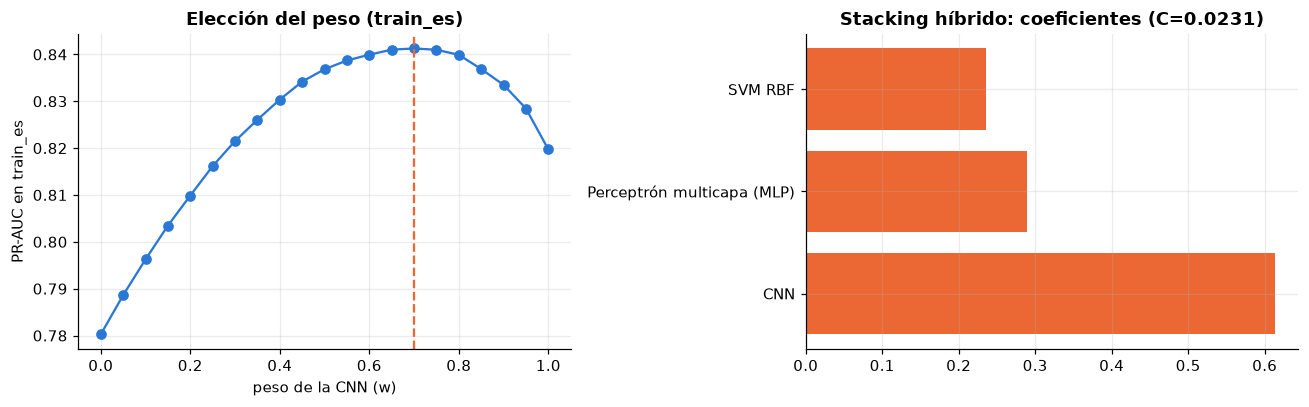

In [ ]:
# 6.- Ajuste de combinadores en train_es
if RUN_HYBRID:
    t0n = HYB_TAB[0]
    def ecdf(ref):
        ref = np.sort(np.asarray(ref)); return lambda x: np.searchsorted(ref, x, side='right') / len(ref)
    hyb = {}
    # Promedio simple
    hyb[f'Híbrido: promedio (CNN + {t0n})'] = (lambda H: 0.5 * H['cnn'] + 0.5 * H[t0n], [CNN_NAME, t0n])
    # Promedio ponderado
    ws = np.round(np.arange(0, 1.0001, 0.05), 2)
    pr_w = [average_precision_score(y_es_h, w * H_es['cnn'] + (1 - w) * H_es[t0n]) for w in ws]
    W_CNN = float(ws[int(np.argmax(pr_w))])
    hyb[f'Híbrido: ponderado w={W_CNN:.2f} (CNN + {t0n})'] = (lambda H, w=W_CNN: w * H['cnn'] + (1 - w) * H[t0n], [CNN_NAME, t0n])
    # Promedio de rangos (ECDF de train_es)
    F_cnn, F_tab = ecdf(H_es['cnn']), ecdf(H_es[t0n])
    hyb[f'Híbrido: rangos (CNN + {t0n})'] = (lambda H: 0.5 * F_cnn(H['cnn']) + 0.5 * F_tab(H[t0n]), [CNN_NAME, t0n])
    # Stacking logístico
    Zc = lambda H: np.column_stack([logit(H[c]) for c in H.columns])
    es_splits = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(H_es, y_es_h, groups=g_es_h))
    meta_h = LogisticRegressionCV(Cs=np.logspace(-3, 2, 12), cv=es_splits, scoring='average_precision', max_iter=5000).fit(Zc(H_es), y_es_h)
    hyb[f'Híbrido: stacking logístico (CNN + {" + ".join(HYB_TAB)})'] = (lambda H: meta_h.predict_proba(Zc(H))[:, 1], [CNN_NAME] + HYB_TAB)

    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    axes[0].plot(ws, pr_w, 'o-', color=CLASS_COLORS[0]); axes[0].axvline(W_CNN, ls='--', color=CLASS_COLORS[1])
    axes[0].set_xlabel('peso de la CNN (w)'); axes[0].set_ylabel('PR-AUC en train_es'); axes[0].set_title('Elección del peso (train_es)')
    cf = pd.Series(meta_h.coef_[0], index=['CNN'] + HYB_TAB)
    axes[1].barh(cf.index, cf.values, color=CLASS_COLORS[1]); axes[1].set_title(f'Stacking híbrido: coeficientes (C={float(np.atleast_1d(meta_h.C_)[0]):.3g})')
    plt.tight_layout(); savefig('ens6_combinadores'); plt.show()

    # Umbral en train_es; evaluación en validación
    for name, (f, comps) in hyb.items():
        p_es_c = np.asarray(f(H_es)); p_va_c = np.asarray(f(H_va))
        register(name, 'híbrido CNN + tabular', p_va_c, best_f1_threshold(y_es_h, p_es_c), np.nan, comps, names=H_va.index)
        RESULTS[name]['PR_AUC_train_es'] = average_precision_score(y_es_h, p_es_c)
    # Referencia: CNN sola y tabular de train_fit sola en el mismo subconjunto
    register(f'{CNN_NAME} (individual)', 'individual CNN', H_va['cnn'], best_f1_threshold(y_es_h, H_es['cnn']), np.nan, [CNN_NAME], names=H_va.index)
    joblib.dump({'hyb_tab': HYB_TAB, 'tab_models_train_fit': hyb_models, 'w_cnn': W_CNN, 'meta': meta_h,
                 'ecdf_ref': {'cnn': np.sort(H_es['cnn'].to_numpy()), t0n: np.sort(H_es[t0n].to_numpy())},
                 'cnn_version': CNN_NAME}, ENS_DIR / 'ensambles_hibridos.joblib')

## 7.- Comparación en validación
Todos los ensambles frente a la CNN (diferencia pareada en las mismas galaxias, IC 95 %). Se incluyen PR-AUC (clasificación) y Brier/ECE (calibración): los promedios de rangos no producen probabilidades calibradas, así que su Brier/ECE no se interpreta como probabilidad.

,familia,n_componentes,PR_AUC_cv_o_train_es,PR_AUC,PR_AUC_IC95_inf,PR_AUC_IC95_sup,F1_barra,Brier,ECE,Δ_vs_CNN,Δ_IC95_inf,Δ_IC95_sup,vs_CNN
modelo,,,,,,,,,,,,,
Híbrido: stacking logístico (CNN + Perceptrón multicapa (MLP) + SVM RBF),híbrido CNN + tabular,3,0.8416,0.8137,0.7772,0.8440,0.7146,0.1255,0.0284,0.0130,0.0027,0.0235,mejor
Híbrido: ponderado w=0.70 (CNN + Perceptrón multicapa (MLP)),híbrido CNN + tabular,2,0.8413,0.8125,0.7756,0.8430,0.7206,0.1290,0.0500,0.0118,0.0028,0.0214,mejor
Híbrido: promedio (CNN + Perceptrón multicapa (MLP)),híbrido CNN + tabular,2,0.8368,0.8096,0.7726,0.8404,0.6977,0.1285,0.0417,0.0088,-0.0047,0.0225,sin diferencia demostrable
Híbrido: rangos (CNN + Perceptrón multicapa (MLP)),híbrido CNN + tabular,2,0.8374,0.8083,0.7708,0.8391,0.7024,0.1628,0.1687,0.0076,-0.0056,0.0207,sin diferencia demostrable
CNN final (individual),individual CNN,1,NaN,0.8007,0.7622,0.8338,0.7282,0.1375,0.0703,NaN,NaN,NaN,NaN
Stacking (metamodelo logístico),heterogéneo tabular,12,0.7757,0.7731,0.7345,0.8072,0.6863,0.1393,0.0220,-0.0277,-0.0514,-0.0026,peor
Votación ponderada (top-3),heterogéneo tabular,3,0.7743,0.7708,0.7337,0.8034,0.6831,0.1422,0.0420,-0.0299,-0.0534,-0.0039,peor
Votación suave (top-3),heterogéneo tabular,3,0.7728,0.7662,0.7287,0.7999,0.6782,0.1443,0.0532,-0.0346,-0.0587,-0.0096,peor
HistGradientBoosting,homogéneo,1,0.7649,0.7645,0.7273,0.7982,0.6861,0.1504,0.0779,-0.0362,-0.0618,-0.0111,peor


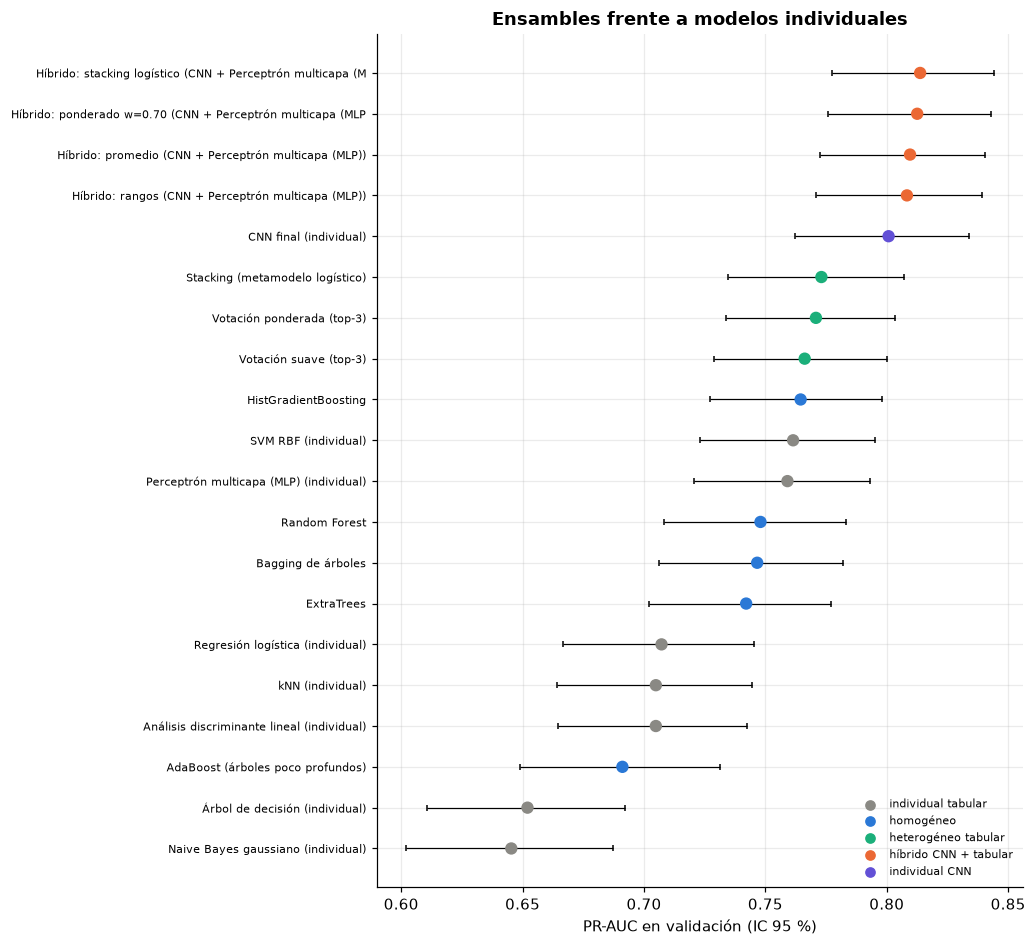

In [ ]:
# 7.- Tabla comparativa
cnn_ref_val = (pd.Series(H_va['cnn'].to_numpy(), index=H_va.index) if RUN_HYBRID else ref_scores.get(CNN_REF))
rows = []
for name, r in RESULTS.items():
    s = r['score']; y = labels_va.reindex(s.index).to_numpy()
    row = {'modelo': name, 'familia': r['familia'], 'n_componentes': len(r['componentes']),
           'PR_AUC_cv_o_train_es': r.get('PR_AUC_train_es', r['PR_AUC_cv']), **full_metrics(y, s.to_numpy(), r['umbral'])}
    if cnn_ref_val is not None and r['familia'] != 'individual CNN':
        d, (lo, hi), n = paired_bootstrap(s, cnn_ref_val, labels_va)
        row.update({'Δ_vs_CNN': d, 'Δ_IC95_inf': lo, 'Δ_IC95_sup': hi,
                    'vs_CNN': 'mejor' if lo > 0 else 'peor' if hi < 0 else 'sin diferencia demostrable'})
    rows.append(row)
ens_val = pd.DataFrame(rows).set_index('modelo').sort_values('PR_AUC', ascending=False)
display(ens_val[['familia', 'n_componentes', 'PR_AUC_cv_o_train_es', 'PR_AUC', 'PR_AUC_IC95_inf', 'PR_AUC_IC95_sup',
                 'F1_barra', 'Brier', 'ECE', 'Δ_vs_CNN', 'Δ_IC95_inf', 'Δ_IC95_sup', 'vs_CNN']].round(4))
ens_val.to_csv(ENS_DIR / 'comparacion_validacion_ensambles.csv')

fam_col = {'individual tabular': NEUTRAL, 'homogéneo': CLASS_COLORS[0], 'heterogéneo tabular': '#1baf7a',
           'híbrido CNN + tabular': CLASS_COLORS[1], 'individual CNN': '#6250d6'}
g = ens_val.sort_values('PR_AUC')
fig, ax = plt.subplots(figsize=(9.5, 0.36 * len(g) + 1.5)); yy = np.arange(len(g))
ax.errorbar(g['PR_AUC'], yy, xerr=[g['PR_AUC'] - g['PR_AUC_IC95_inf'], g['PR_AUC_IC95_sup'] - g['PR_AUC']], fmt='none', ecolor='black', capsize=2, lw=.8)
ax.scatter(g['PR_AUC'], yy, s=50, zorder=3, color=[fam_col[f] for f in g['familia']])
ax.set_yticks(yy, [i[:58] for i in g.index], fontsize=7); ax.set_xlabel('PR-AUC en validación (IC 95 %)')
for f, c in fam_col.items(): ax.scatter([], [], color=c, label=f)
ax.legend(frameon=False, fontsize=7, loc='lower right'); ax.set_title('Ensambles frente a modelos individuales')
plt.tight_layout(); savefig('ens7_comparacion'); plt.show()

In [ ]:
# 7.1.- ¿Dónde se complementan la CNN y el modelo tabular? Desacuerdos por código Bars (validación)
if RUN_HYBRID:
    bars_va = data.set_index('name').loc[H_va.index, 'Bars']
    thr_c = RESULTS[f'{CNN_NAME} (individual)']['umbral']; thr_t = best_f1_threshold(y_es_h, H_es[t0n])
    pc, pt = (H_va['cnn'] >= thr_c).astype(int), (H_va[t0n] >= thr_t).astype(int)
    yv = labels_va[H_va.index]
    comp = pd.DataFrame({'Bars': bars_va.map(BARS_SHORT),
                         'ambos aciertan': (pc == yv) & (pt == yv), 'solo CNN acierta': (pc == yv) & (pt != yv),
                         'solo tabular acierta': (pc != yv) & (pt == yv), 'ambos fallan': (pc != yv) & (pt != yv)})
    tabc = comp.groupby('Bars')[['ambos aciertan', 'solo CNN acierta', 'solo tabular acierta', 'ambos fallan']].mean()
    tabc['n'] = comp.groupby('Bars').size()
    display(tabc.round(3)); tabc.to_csv(ENS_DIR / 'complementariedad_por_bars.csv')
    print(f'Errores no compartidos (oportunidad de un ensamble): solo CNN acierta {comp["solo CNN acierta"].mean():.3f} · '
          f'solo tabular acierta {comp["solo tabular acierta"].mean():.3f} · ambos fallan {comp["ambos fallan"].mean():.3f}')

,ambos aciertan,solo CNN acierta,solo tabular acierta,ambos fallan,n
Bars,,,,,
débil,0.387,0.177,0.081,0.355,62
muy evidente,0.764,0.051,0.092,0.092,195
prominente,0.621,0.121,0.106,0.152,66
sin barra,0.698,0.170,0.030,0.102,915
visible,0.588,0.097,0.155,0.159,226


Errores no compartidos (oportunidad de un ensamble): solo CNN acierta 0.141 · solo tabular acierta 0.063 · ambos fallan 0.122


## 8.- Medidas suaves y elección del candidato
Un ensamble suma costos: más modelos que mantener, más tiempo de inferencia y menos explicabilidad. Regla de elección (fijada antes de ver los resultados):
1. Candidatos: ensambles cuya diferencia con la CNN en validación tenga IC 95 % **por encima de 0**.
2. Entre ellos, el de mayor PR-AUC; ante diferencias no demostrables entre candidatos, el de **menos componentes**.
3. Si ninguno supera a la CNN de forma demostrable, **se conserva la CNN** como modelo final y no se vuelve a consultar el conjunto de prueba.

Nota: elegir entre muchos ensambles con validación introduce sesgo de selección; el PR-AUC de validación del elegido es optimista. Por eso la estimación final sería la de prueba.

In [ ]:
# 8.- Costos y elección
def tab_ms_per_image(models, n=300):
    Xs = X_va.iloc[:n]; t0 = time.perf_counter()
    for m in models: m.predict_proba(Xs)
    return (time.perf_counter() - t0) / n * 1000
def mb(obj):
    buf = io.BytesIO(); joblib.dump(obj, buf); return buf.getbuffer().nbytes / 1024**2
cnn_ms = np.nan
if (CNN_DIR / 'recursos_cnn.csv').exists():
    rc = pd.read_csv(CNN_DIR / 'recursos_cnn.csv', index_col=0)
    try:
        cnn_ms = float(rc.loc['ms_por_1000_pred_mps'].iloc[0]) / 1000 + float(rc.loc['ms_preprocesamiento_por_imagen'].iloc[0])
    except Exception:
        pass
print('ms/imagen de la CNN (CNN-11):', cnn_ms)
model_of = {**alt['models'], **{n: homog[n]['search'].best_estimator_ for n in HOMOG}}
if RUN_HYBRID: model_of.update({f'{n}@train_fit': m for n, m in hyb_models.items()})
cost_rows = []
for name, r in RESULTS.items():
    comps = r['componentes']
    uses_cnn = any(c.startswith('CNN') for c in comps)
    tabs = [model_of[c if not (RUN_HYBRID and r['familia'] == 'híbrido CNN + tabular') else f'{c}@train_fit']
            for c in comps if not c.startswith('CNN')]
    cost_rows.append({'modelo': name, 'n_componentes': len(comps), 'usa_CNN': uses_cnn, 'usa_características': bool(tabs),
                      'ms_por_imagen': (FEATURE_MS_PER_IMAGE + tab_ms_per_image(tabs) if tabs else 0) + (cnn_ms if uses_cnn else 0),
                      'MB_modelos_tabulares': sum(mb(t) for t in tabs)})
costs = pd.DataFrame(cost_rows).set_index('modelo')
summary_ens = ens_val[['familia', 'PR_AUC', 'PR_AUC_IC95_inf', 'PR_AUC_IC95_sup', 'ECE', 'Δ_vs_CNN', 'Δ_IC95_inf', 'vs_CNN']].join(costs)
display(summary_ens.round(3)); summary_ens.to_csv(ENS_DIR / 'resumen_ensambles_medidas_suaves.csv')

candidates = summary_ens[(summary_ens['Δ_IC95_inf'] > 0) & (summary_ens['familia'] != 'individual CNN')]
if len(candidates):
    best = candidates['PR_AUC'].idxmax()
    ties = [c for c in candidates.index if c != best and
            paired_bootstrap(RESULTS[c]['score'], RESULTS[best]['score'], labels_va)[1][1] > 0]   # no demostrablemente peor
    CHOSEN = min([best] + ties, key=lambda c: (candidates.loc[c, 'n_componentes'], -candidates.loc[c, 'PR_AUC']))
    print(f'Candidato elegido: {CHOSEN}')
else:
    CHOSEN = None
    print('Ningún ensamble supera a la CNN de forma demostrable en validación → se conserva la CNN; no se consulta prueba.')
json.dump({'elegido': CHOSEN}, open(ENS_DIR / 'candidato_elegido.json', 'w'), ensure_ascii=False)

ms/imagen de la CNN (CNN-11): 25.78302605497811


,familia,PR_AUC,PR_AUC_IC95_inf,PR_AUC_IC95_sup,ECE,Δ_vs_CNN,Δ_IC95_inf,vs_CNN,n_componentes,usa_CNN,usa_características,ms_por_imagen,MB_modelos_tabulares
modelo,,,,,,,,,,,,,
Híbrido: stacking logístico (CNN + Perceptrón multicapa (MLP) + SVM RBF),híbrido CNN + tabular,0.814,0.777,0.844,0.028,0.013,0.003,mejor,3,True,True,115.974,1.058
Híbrido: ponderado w=0.70 (CNN + Perceptrón multicapa (MLP)),híbrido CNN + tabular,0.813,0.776,0.843,0.050,0.012,0.003,mejor,2,True,True,115.792,0.116
Híbrido: promedio (CNN + Perceptrón multicapa (MLP)),híbrido CNN + tabular,0.810,0.773,0.840,0.042,0.009,-0.005,sin diferencia demostrable,2,True,True,115.792,0.116
Híbrido: rangos (CNN + Perceptrón multicapa (MLP)),híbrido CNN + tabular,0.808,0.771,0.839,0.169,0.008,-0.006,sin diferencia demostrable,2,True,True,115.790,0.116
CNN final (individual),individual CNN,0.801,0.762,0.834,0.070,NaN,NaN,NaN,1,True,False,25.783,0.000
Stacking (metamodelo logístico),heterogéneo tabular,0.773,0.734,0.807,0.022,-0.028,-0.051,peor,12,False,True,91.110,49.147
Votación ponderada (top-3),heterogéneo tabular,0.771,0.734,0.803,0.042,-0.030,-0.053,peor,3,False,True,90.288,9.774
Votación suave (top-3),heterogéneo tabular,0.766,0.729,0.800,0.053,-0.035,-0.059,peor,3,False,True,90.295,9.774
HistGradientBoosting,homogéneo,0.765,0.727,0.798,0.078,-0.036,-0.062,peor,1,False,True,90.083,1.667


Candidato elegido: Híbrido: ponderado w=0.70 (CNN + Perceptrón multicapa (MLP))


## 9.- Evaluación final en prueba — solo el candidato elegido, una vez
**Segunda consulta al conjunto de prueba** (la primera fue CNN-14). Solo se ejecuta si `RUN_FINAL_TEST = True` y hay un candidato elegido en el paso 8. Se reporta junto con la CNN en las mismas galaxias de prueba. Cambiar decisiones después de ver este resultado invalidaría la estimación.

In [ ]:
# 9.- Prueba (protegida)
if RUN_FINAL_TEST and CHOSEN is not None:
    test = data[data['split'] == 'test'].reset_index(drop=True)
    fam = RESULTS[CHOSEN]['familia']; thr = RESULTS[CHOSEN]['umbral']
    if fam == 'híbrido CNN + tabular':
        te_rows = test[test['name'].isin(cnn_scores.index)]
        p_te = np.asarray(hyb[CHOSEN][0](hyb_inputs(te_rows))); names_te = te_rows['name']
    else:
        names_te = test['name']
        P = {n: model_of[n].predict_proba(test[FEATURES])[:, 1] for n in DIV_NAMES}
        if CHOSEN.startswith('Votación suave'): p_te = np.mean([P[n] for n in top], axis=0)
        elif CHOSEN.startswith('Votación ponderada'): p_te = sum(w * P[n] for w, n in zip(best_w, top))
        elif CHOSEN.startswith('Stacking'): p_te = meta.predict_proba(np.column_stack([logit(P[n]) for n in DIV_NAMES]))[:, 1]
        else: p_te = P[CHOSEN.replace(' (individual)', '')]
    y_te = test.set_index('name').loc[names_te, 'label'].to_numpy()
    res = {CHOSEN: full_metrics(y_te, p_te, thr)}
    s_ch = pd.Series(p_te, index=names_te.to_numpy()); lab_te = pd.Series(y_te, index=names_te.to_numpy())
    if RUN_HYBRID:
        cnn_te = cnn_scores[cnn_scores['cnn_split'] == 'test']['cnn_score']
        common = s_ch.index.intersection(cnn_te.index)
        res[CNN_NAME] = full_metrics(lab_te[common].to_numpy(), cnn_te[common].to_numpy(), RESULTS[f'{CNN_NAME} (individual)']['umbral'])
        d, (lo, hi), n = paired_bootstrap(s_ch, cnn_te, lab_te)
        print(f'Δ PR-AUC en prueba ({CHOSEN} − {CNN_NAME}) = {d:+.4f}  IC95 [{lo:+.4f}, {hi:+.4f}]  (n={n})')
    test_res = pd.DataFrame(res).T
    display(test_res.round(4)); test_res.to_csv(ENS_DIR / 'evaluacion_final_prueba_ensamble.csv')
    print('Segunda consulta al conjunto de prueba registrada. No modificar decisiones a partir de este resultado.')
elif CHOSEN is None:
    print('Sin candidato: el modelo final sigue siendo la CNN evaluada en CNN-14.')
else:
    print('RUN_FINAL_TEST = False: prueba no consultada.')

Δ PR-AUC en prueba (Híbrido: ponderado w=0.70 (CNN + Perceptrón multicapa (MLP)) − CNN final) = +0.0181  IC95 [+0.0068, +0.0301]  (n=1464)


,PR_AUC,PR_AUC_IC95_inf,PR_AUC_IC95_sup,ROC_AUC,umbral,F1_barra,precision_barra,recall_barra,exactitud_bal,Brier,ECE
Híbrido: ponderado w=0.70 (CNN + Perceptrón multicapa (MLP)),0.8243,0.7938,0.8526,0.8924,0.4399,0.7323,0.6633,0.8172,0.8052,0.1262,0.0552
CNN final,0.8062,0.7734,0.8382,0.8808,0.5328,0.7139,0.6765,0.7556,0.7878,0.1371,0.0746


Segunda consulta al conjunto de prueba registrada. No modificar decisiones a partir de este resultado.


## Conclusiones de ensambles

**1. Ensambles homogéneos (árboles).**
- **Frente al árbol individual:** los cinco ensambles de árboles superan al árbol de decisión individual (PR-AUC en validación 0.652), en su mayoría por 0.09–0.11, porque combinar árboles corrige su inestabilidad.
- **Ranking:**
  - HistGradientBoosting es el mejor: 0.767 en CV y 0.765 en validación;
  - le siguen Random Forest (0.748), *bagging* (0.747) y ExtraTrees (0.742);
  - AdaBoost, con árboles poco profundos, subajusta (0.691).
- **Frente a los mejores individuales:** el mejor ensamble de árboles queda al nivel de los mejores modelos individuales (MLP 0.759, SVM 0.761). Ninguna familia tabular se separa: el techo de ≈ 0.76 lo imponen las características, no el algoritmo.

**2. Diversidad y ensambles heterogéneos tabulares.**
- **Correlación:** los modelos tabulares están muy correlacionados (Spearman ≥ 0.8 en casi todos los pares), porque comparten las mismas 34 características. Hay pares casi redundantes, como regresión logística y LDA (0.99) o Random Forest y *bagging* (1.00).
- **Pesos del *stacking*:** el *stacking* tabular da más peso a HistGradientBoosting, al MLP, al *bagging* y a ExtraTrees, y deja en cero a los redundantes. Sus coeficientes negativos reflejan la colinealidad entre modelos, no un efecto perjudicial.
- **Desempeño:** el mejor ensamble tabular, el *stacking* (0.773), mejora ligeramente a los individuales, pero queda por debajo de la CNN de forma demostrable (Δ −0.028 [−0.051, −0.003]). Combinar modelos que ven las mismas características no supera el techo de ≈ 0.77.

**3. Ensambles híbridos CNN + tabular.**
- **Diseño sin fuga:** el combinador se ajustó en `train_es` (975 galaxias), con el MLP y la SVM reentrenados solo con `train_fit`. Las puntuaciones recalculadas de la CNN coinciden con las del notebook de la CNN (diferencia máxima 3·10⁻⁸).
- **Sesgo de `train_es`:** los tres modelos rinden ≈ 0.02 más en `train_es` que en validación, lo que indica que la participación previa de `train_es` en las decisiones de la CNN no la favoreció de forma apreciable.
- **Diversidad:** la correlación entre la CNN y los tabulares (0.79–0.80) es menor que la de los tabulares entre sí (≥ 0.9). La CNN aporta información distinta.
- **Resultados en validación:**
  - superan a la CNN (0.801) de forma demostrable el *stacking* logístico de CNN, MLP y SVM (0.814, Δ +0.013 [+0.003, +0.024]) y el promedio ponderado de CNN y MLP (0.813, Δ +0.012 [+0.003, +0.021]);
  - el promedio simple y el de rangos, que dan igual peso a ambos modelos, no alcanzan una mejora demostrable;
  - la ganancia en validación es la mitad de la observada en `train_es` (≈ +0.021), donde se eligieron los pesos.

**4. Por qué funciona el híbrido.**
- **Coincidencia y desacuerdo:** en validación la CNN y el MLP coinciden en el 67 % de las galaxias, solo la CNN acierta en el 14.1 %, solo el MLP en el 6.3 % y ambos fallan en el 12.2 %.
- **Fortalezas de cada modelo:**
  - la CNN es superior para rechazar galaxias sin barra (acierta sola en el 17 %, frente al 3 % del MLP);
  - el MLP aporta más en barras visibles (Bars = 0.5; 15.5 % frente a 9.7 %);
  - las barras débiles son el grupo más difícil (ambos fallan en el 35.5 %, n = 62), porque están en el límite entre las dos clases de la etiqueta.
- **Hipótesis no verificada:** las características diseñadas (elipticidad de isofotas, modo de Fourier m = 2) capturarían mejor la estructura alargada de barras moderadas.

**5. Elección y evaluación en prueba.** Por la regla fijada de antemano (mejora demostrable frente a la CNN y, entre candidatos sin diferencia demostrable, el de menos componentes) se eligió el **promedio ponderado: 0.70 × CNN + 0.30 × MLP**, con umbral 0.44 elegido en `train_es`. Se evaluó una sola vez en prueba, la segunda consulta a ese conjunto en el proyecto:

| Prueba (1 464) | Híbrido ponderado | CNN |
|---|---|---|
| PR-AUC [IC 95 %] | 0.824 [0.794, 0.853] | 0.806 [0.773, 0.838] |
| ROC-AUC | 0.892 | 0.881 |
| F1 / precisión / recall | 0.732 / 0.663 / 0.817 | 0.714 / 0.677 / 0.756 |
| Exactitud balanceada | 0.805 | 0.788 |
| Brier / ECE | 0.126 / 0.055 | 0.137 / 0.075 |

La diferencia pareada es **+0.018 [+0.007, +0.030]**: la mejora se confirma con datos no usados en ninguna decisión, y es algo mayor que en validación. Con el umbral elegido, el híbrido recupera más barras (recall +0.06) a cambio de una pequeña pérdida de precisión (−0.013), y está mejor calibrado.

**6. Medidas suaves.**
- **Costo por imagen:** el híbrido requiere extraer las características (≈ 90 ms) además de ejecutar la CNN. Con GPU tarda ≈ 116 ms por imagen frente a 26 ms de la CNN sola (≈ 4.5 veces más); sin GPU, ≈ 320 ms frente a 230 ms.
- **Tamaño:** el componente tabular agrega solo 0.12 MB a los 42.7 MB de la CNN.
- **Mantenimiento:** el sistema depende de dos tuberías (imagen y características) en lugar de una.
- **Alternativa:** el *stacking* híbrido, no elegido por tener un componente más, está mejor calibrado (ECE 0.028 en validación). Sería preferible si las puntuaciones se usaran como probabilidades.

**7. Decisión.** El **modelo final del proyecto es el ensamble híbrido ponderado (0.70 CNN + 0.30 MLP)**. Supera a la CNN de forma demostrable en validación y en prueba, aunque la mejora es modesta (≈ 2 puntos de PR-AUC) y cuesta más latencia y complejidad. La CNN sola queda como alternativa cuando importan la velocidad o la simplicidad.

**Limitaciones.**
- **Uso de prueba:** el conjunto de prueba se consultó dos veces en el proyecto (CNN-14 y este ensamble), ambas con decisiones fijadas de antemano y declaradas.
- **Tamaño del combinador:** se ajustó con solo 975 galaxias.
- **Selección:** se eligió entre varios híbridos en validación.
- **Validez:** los resultados valen para SDSS r a 0.4″/px y z ≤ 0.15. Las predicciones reproducen el criterio visual de los clasificadores humanos; no constituyen una detección física de barras.

# Declaración de uso de IA y contribución del equipo

### Uso de herramientas de IA

| Herramienta utilizada | Propósito de uso | Alcance del apoyo (celdas o secciones) | Responsabilidad: qué revisó o validó el equipo |
|---|---|---|---|
| Anthropic. (2026). Claude (Opus 5.5) [Modelo de lenguaje grande].<br>https://claude.ai/  | Completar código de gráficas | Celdas 5,6,9 | Ejes y escalas corregidos; actualizacion de graficos |
| Anthropic. (2026). Claude (Opus 5.5) [Modelo de lenguaje grande].<br>https://claude.ai/  | Optimizar el codigo | Sección 1,2,3,4,5,6,7,8 | Se mejoraron las funciones utilizadas dentro del programa|

### Contribución individual

| Integrante | Contribución al avance |
|---|---|
| Valente Cortes Aceves | Preparó los datos y documentó los resultados del modleos de ensamble. |
| Francisco Vazquez Martinez | Desarrolló las visualizaciones y analizó los patrones identificados. |
| Rogelio Geovanni Licona Hernandez | Comparó alternativas metodológicas y documentó los criterios utilizados para seleccionar la estrategia final. |

### Decisiones principales

<small>Documenten las tres decisiones que más influyeron en el avance, indicando qué alternativa se descartó.</small>

<small><b>Decisión 1:</b> Entrenar el combinador de los ensambles híbridos en el subconjunto interno `train_es`, con los modelos tabulares reentrenados solo con `train_fit`</small>

- <small>Justificación: La CNN se entrenó con `train_fit`, así que sus predicciones en esas galaxias son optimistas (las memorizó). Para que el combinador aprenda con galaxias que ningún modelo vio al entrenar, los modelos tabulares del híbrido se reentrenaron solo con `train_fit` y el combinador se ajustó en `train_es`. Validación queda intacta para comparar.</small>
- <small>Alternativa descartada y motivo: Ajustar el combinador con las predicciones de todo el entrenamiento. Se descartó porque habría fuga de información: el combinador daría demasiado peso a la CNN por su desempeño inflado en datos que ya conocía.</small>

<small><b>Decisión 2:</b> Construir los ensambles de árboles en este notebook y compararlos con el árbol de decisión individual</small>

- <small>Justificación: Random Forest, ExtraTrees e HistGradientBoosting combinan muchos árboles, así que pertenecen a esta fase y no a la de modelos individuales. Compararlos con el árbol individual del notebook de alternativos mide directamente cuánto aporta combinar árboles.</small>
- <small>Alternativa descartada y motivo: Mantenerlos entre los modelos alternativos. Se descartó porque la actividad de modelos alternativos exige modelos individuales, no ensambles.</small>

<small><b>Decisión 3:</b> Adoptar un ensamble solo si supera a la CNN de forma demostrable en validación, y consultar prueba solo para ese candidato</small>

- <small>Justificación: Un ensamble suma costos (más modelos que mantener, extracción de características más CNN, menor explicabilidad), así que debe justificarlo con una mejora cuyo IC 95 % excluya 0. Entre candidatos sin diferencia demostrable se elige el de menos componentes. Si ninguno supera a la CNN, se conserva la CNN y no se vuelve a consultar prueba. Resultado: dos híbridos superaron a la CNN en validación; por tener menos componentes se eligió el promedio ponderado (0.70 CNN + 0.30 MLP), con PR-AUC 0.813 frente a 0.801. En la única evaluación en prueba obtuvo 0.824 frente a 0.806 de la CNN (Δ +0.018, IC 95 % [+0.007, +0.030]).</small>
- <small>Alternativa descartada y motivo: Elegir el ensamble con mayor PR-AUC puntual en validación. Se descartó porque, al comparar muchos ensambles, el máximo es optimista por sesgo de selección y podría adoptarse una mejora que solo es ruido.</small>